# AMO - wyznaczanie położenia odbiornika na podstawie danych z systemu GPS
Autor: Piotr Patek

In [111]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from dotenv import load_dotenv

load_dotenv()
AMPL_LICENSE_UID = os.getenv("AMPL_LICENSE_UID")

from amplpy import ampl_notebook
ampl = ampl_notebook(
    modules=["minos"],
    license_uuid=AMPL_LICENSE_UID)

R = 6378137.0      # [m]
C = 299792458.0    # [m/s]

Licensed to AMPL for Academics - Piotr Patek <piotr.patek.stud@pw.edu.pl>.


In [112]:
data = pd.read_csv("dane_79.csv", delimiter=";")
thetas = data["Szerokość dziesiętna [°]"].to_numpy()
phis = data["Długość dziesiętna [°]"].to_numpy()
heights = data["Wysokość n.p.m. [m]"].to_numpy()
taus = data["Czas nadejścia sygnału GPS [s]"].to_numpy()
N = len(taus)
data

,Nr satelity,Szerokość dziesiętna [°],Długość dziesiętna [°],Szerokość kątowa,Długość kątowa,Wysokość n.p.m. [m],Czas nadejścia sygnału GPS [s]
0,G02,-7.960410,39.772868,7° 57′ 37.47743″ S,39° 46′ 22.32315″ E,2.047210e+07,0.081862
1,G03,54.147155,36.755840,54° 08′ 49.75958″ N,36° 45′ 21.02518″ E,2.002536e+07,0.067206
2,G04,31.574863,6.277985,31° 34′ 29.50585″ N,6° 16′ 40.74640″ E,2.027735e+07,0.069845
3,G06,53.685182,-74.503820,53° 41′ 06.65409″ N,74° 30′ 13.75166″ W,2.021495e+07,0.077748
4,G09,9.485417,-15.627469,9° 29′ 07.50187″ N,15° 37′ 38.88767″ W,2.021291e+07,0.077386
5,G17,19.514551,-32.082185,19° 30′ 52.38322″ N,32° 04′ 55.86544″ W,2.044935e+07,0.078258
6,G19,40.510719,-52.275842,40° 30′ 38.58791″ N,52° 16′ 33.03002″ W,1.997215e+07,0.075826
7,G28,54.723458,117.946860,54° 43′ 24.44839″ N,117° 56′ 48.69438″ E,2.018119e+07,0.077717


## Układ równań

Położenie satelit podane jest we współrzędnych geograficznych za pomocą szerokości geograficznej $\theta$, długości geograficznej $\phi$ oraz wysokości $h$.
Aby wyznaczyć położenie i-tego satelity we współrzędnych kartezjańskich $(x, y, z)$ stosujemy przekształcenie:

$$
S_i = [x, y, z]^T = (R + h_i)\begin{bmatrix} \cos\theta_i \cos\phi_i \\ \cos\theta_i \sin\phi_i \\ \sin\theta_i \end{bmatrix}, \qquad i = 1, \dots, N
$$

Szukamy położenia odbiornika $X = (x, y, z)$ oraz błędu zegara odbiornika $b$ [s].
Sygnał od satelity $i$ przebywa drogę $c(\tau_i + b)$, gdzie $\tau_i = \tilde{t_r} - t_i$ to zmierzony czas, więc:

$$
\sqrt{(x - x_i)^2 + (y - y_i)^2 + (z - z_i)^2} = c\,(\tau_i + b), \qquad i = 1, \dots, N
$$


In [113]:
def geo2cart(theta, phi, h):
    th, ph = np.radians(theta), np.radians(phi)
    r = R + np.asarray(h, dtype=float)
    return np.column_stack([r * np.cos(th) * np.cos(ph),
                            r * np.cos(th) * np.sin(ph),
                            r * np.sin(th)])

def cart2geo(X):
    x, y, z = X
    r = np.sqrt(x * x + y * y + z * z)
    return np.degrees(np.arcsin(z / r)), np.degrees(np.arctan2(y, x)), r - R

S = geo2cart(thetas, phis, heights)

## Zadanie optymalizacji – metoda najmniejszych kwadratów

Zmienne: $u = (x, y, z, \beta)$, gdzie $\beta = c\,b$ [m]. Opóźnienie zegara $b$ zostało przemnożone dodatkowo przez $c$ ze względów numerycznych. Zmienne położenia są wyrażone w metrach i są rzędu $10^6$, natomiast samo opóźnienie jest bardzo małą liczbą.

Residua:

$$
r_i(u) = d_i - \beta - c\,\tau_i, \qquad d_i = \|X - S_i\|
$$

Zadanie bez ograniczeń:

$$
\min_{u \in \mathbb{R}^4} F(u) = \frac{1}{2} \sum_{i=1}^{N} r_i(u)^2
$$

Residua są nieliniowe, więc potrzebne jest wyznaczenie macierzy pierwszych pochodnych (jakobianu). Po przekształceniach i-ty wiersz tego jakobianu o wymiarach $(N \times 4 )$ wygląda następująco:

$$
J_i = \begin{bmatrix} \dfrac{(X - S_i)^T}{d_i} & - 1 \end{bmatrix}
$$

Natomiast cały jakobian ma postać:

$$
J(u) = \frac{\partial r}{\partial u} =
\begin{bmatrix}
\dfrac{x - x_1}{d_1} & \dfrac{y - y_1}{d_1} & \dfrac{z - z_1}{d_1} & -1 \\[3mm]
\dfrac{x - x_2}{d_2} & \dfrac{y - y_2}{d_2} & \dfrac{z - z_2}{d_2} & -1 \\[2mm]
\vdots & \vdots & \vdots & \vdots \\[1mm]
\dfrac{x - x_N}{d_N} & \dfrac{y - y_N}{d_N} & \dfrac{z - z_N}{d_N} & -1
\end{bmatrix}
$$

## Rozwiązanie - algorytm Levenberg-Marquardt

In [114]:
def residuals(u, S, tau):
    return np.linalg.norm(S - u[:3], axis=1) - u[3] - C * tau

def jacobian(u, S, tau):
    d = u[:3] - S
    return np.hstack([d / np.linalg.norm(d, axis=1)[:, None], -np.ones((len(tau), 1))])

def solve_lm(S, taus, u0=np.zeros(4), tol=1e-12):
    res = least_squares(residuals, u0, jac=jacobian, args=(S, taus),
                        method="lm", xtol=tol, ftol=tol, gtol=tol)
    X = res.x[:3]
    theta, phi, h = cart2geo(X)
    return {"status": res.message, "F": res.cost, "nfev": res.nfev,
            "X": X, "b": res.x[3] / C, "theta": theta, "phi": phi, "h": h}

In [115]:
res_lm = solve_lm(S, taus)
X_ref = res_lm["X"]
res_lm

{'status': '`xtol` termination condition is satisfied.',
 'F': np.float64(1.7664177828780048e-09),
 'nfev': 22,
 'X': array([3661690.66198847, 1384580.30314586, 5035593.34417618]),
 'b': np.float64(1.631772249687627e-13),
 'theta': np.float64(52.1381450000344),
 'phi': np.float64(20.712906666912605),
 'h': np.float64(126.19995220005512)}

## Rozwiązanie - solver MINOS z AMPL
Definujemy model MNK wraz z przekształceniem do 

In [116]:
%%ampl_eval
reset;

param N integer > 0;
param R := 6378137;      # [m]
param c := 299792458;    # [m/s]
param pi := 4*atan(1);

param Sx  {1..N};         # [m]
param Sy  {1..N};         # [m]
param Sz  {1..N};         # [m]
param tau {1..N};         # [s]

var x;
var y;
var z;
var beta;                 # beta = c*b [m]

minimize F:
    0.5 * sum {i in 1..N}
        ( sqrt((x - Sx[i])^2 + (y - Sy[i])^2 + (z - Sz[i])^2) - beta - c*tau[i] )^2;

In [ ]:
def set_ampl_data(S, taus):
    ampl.param["N"] = len(taus)
    ampl.param["Sx"] = {i + 1: float(v[0]) for i, v in enumerate(S)}
    ampl.param["Sy"] = {i + 1: float(v[1]) for i, v in enumerate(S)}
    ampl.param["Sz"] = {i + 1: float(v[2]) for i, v in enumerate(S)}
    ampl.param["tau"] = {i + 1: float(v) for i, v in enumerate(taus)}

def solve_minos(S, taus, u0=np.zeros(4), tol=1e-12, verbose=False):
    set_ampl_data(S, taus)
    ampl.option["solver"] = "minos"
    ampl.option["minos_options"] = (f"optimality_tolerance={tol} feasibility_tolerance={tol} "
                                    f"major_iterations=500 outlev={int(verbose)}")

    x0, y0, z0, b0 = np.asarray(u0, dtype=float)
    ampl.eval(f"let x := {x0}; let y := {y0}; let z := {z0}; let beta := {b0};")
    ampl.solve(verbose=verbose)

    X = np.array([ampl.get_value(v) for v in ("x", "y", "z")])
    theta, phi, h = cart2geo(X)
    return {"status": ampl.solve_result, "F": ampl.get_value("F"), "nfev": None,
            "X": X, "b": ampl.get_value("beta") / C, "theta": theta, "phi": phi, "h": h}

In [118]:
res_minos = solve_minos(S, taus, verbose=True)
res_minos

MINOS 5.51: optimality_tolerance=1e-10
feasibility_tolerance=1e-10
major_iterations=500
outlev=1
MINOS 5.51: optimal solution found.
16 iterations, objective 1.766576441e-09
Nonlin evals: obj = 32, grad = 31.


{'status': 'solved',
 'F': 1.7665764406871176e-09,
 'nfev': None,
 'X': array([3661690.66198848, 1384580.30314586, 5035593.3441762 ]),
 'b': 1.6314149505275176e-13,
 'theta': np.float64(52.13814500003441),
 'phi': np.float64(20.71290666691254),
 'h': np.float64(126.19995221775025)}

## Porównanie wyników

In [119]:
pd.DataFrame({
    "LM (scipy)": [res_lm[k] for k in ("theta", "phi", "h", "b", "F")],
    "MINOS (AMPL)": [res_minos[k] for k in ("theta", "phi", "h", "b", "F")],
}, index=["theta [°]", "phi [°]", "h [m]", "b [s]", "F [m²]"])

,LM (scipy),MINOS (AMPL)
theta [°],5.213815e+01,5.213815e+01
phi [°],2.071291e+01,2.071291e+01
h [m],1.262000e+02,1.262000e+02
b [s],1.631772e-13,1.631415e-13
F [m²],1.766418e-09,1.766576e-09


In [120]:
print(f"|X_LM - X_MINOS| = {np.linalg.norm(res_lm['X'] - res_minos['X']):.3e} m")
for name, r in [("LM", res_lm), ("MINOS", res_minos)]:
    print(f"{name:6s} https://www.google.com/maps?q={r['theta']:.6f},{r['phi']:.6f}")

|X_LM - X_MINOS| = 1.812e-08 m
LM     https://www.google.com/maps?q=52.138145,20.712907
MINOS  https://www.google.com/maps?q=52.138145,20.712907


Wyznaczony punkt ($\theta \approx 52.138145°$ N, $\phi \approx 20.712907°$ E, $h \approx 126$ m n.p.m.) leży w okolicy Brwinowa (woj. mazowieckie, ok. 25 km na zachód od Warszawy).
Błąd zegara $b$ wyszedł praktycznie zerowy.

Różnica pomiędzy dwoma rozwiazaniami jest na tyle mała, że możnaby uznać ją za pomijalną biorąc pod uwagę błąd pozycjonowania samego GPS, który wnosi dla normalnych odbiorników kilka metrów, a dla precyzyjnych odbiorników GPS pojedyncze centymetry, a więc i tak jest większy niż różnica rzędu $10^{-8}$

## Testy

Punkt odniesienia: $X_{ref}$ – rozwiązanie LM z tolerancją $10^{-12}$. Błąd rozwiązania to $\|X - X_{ref}\|$ [m] (na wykresach logarytmicznych błąd 0 pokazany jako $10^{-12}$).

In [121]:
solvers = {"LM": solve_lm, "MINOS": solve_minos}
err = lambda r: np.linalg.norm(r["X"] - X_ref)

### Wpływ punktu startowego

In [122]:
starts = {
    "środek Ziemi": np.zeros(3),
    "Warszawa": geo2cart([52.21], [21.01], [0])[0],
    "biegun płn.": geo2cart([90], [0], [0])[0],
    "Nowa Zelandia (Wellington)": geo2cart([-41.29], [174.78], [0])[0],
    "losowy": np.random.default_rng(1).normal(0, 1e7, 3),
    "środek satelitów": S.mean(axis=0),
}

rows = []
for start, X0 in starts.items():
    for name, solve in solvers.items():
        r = solve(S, taus, u0=np.r_[X0, 0.0])
        rows.append({"start": start, "solver": name, "theta [°]": r["theta"], "phi [°]": r["phi"],
                     "błąd [m]": err(r), "nfev": r["nfev"], "status": r["status"]})
df_start = pd.DataFrame(rows)
df_start

,start,solver,theta [°],phi [°],błąd [m],nfev,status
0,środek Ziemi,LM,52.138145,20.712907,0.000000e+00,22.0,`xtol` termination condition is satisfied.
1,środek Ziemi,MINOS,52.138145,20.712907,1.812045e-08,NaN,solved
2,Warszawa,LM,52.138145,20.712907,3.461276e-09,4.0,`xtol` termination condition is satisfied.
3,Warszawa,MINOS,52.138145,20.712907,2.973312e-08,NaN,solved
4,biegun płn.,LM,52.138145,20.712907,4.861647e-09,6.0,`xtol` termination condition is satisfied.
5,biegun płn.,MINOS,52.138145,20.712907,5.967918e-09,NaN,solved
6,Nowa Zelandia (Wellington),LM,52.138145,20.712907,2.879956e-09,7.0,`xtol` termination condition is satisfied.
7,Nowa Zelandia (Wellington),MINOS,52.138145,20.712907,2.304435e-08,NaN,solved
8,losowy,LM,52.138145,20.712907,2.095476e-09,7.0,`xtol` termination condition is satisfied.
9,losowy,MINOS,52.138145,20.712907,4.261246e-08,NaN,solved


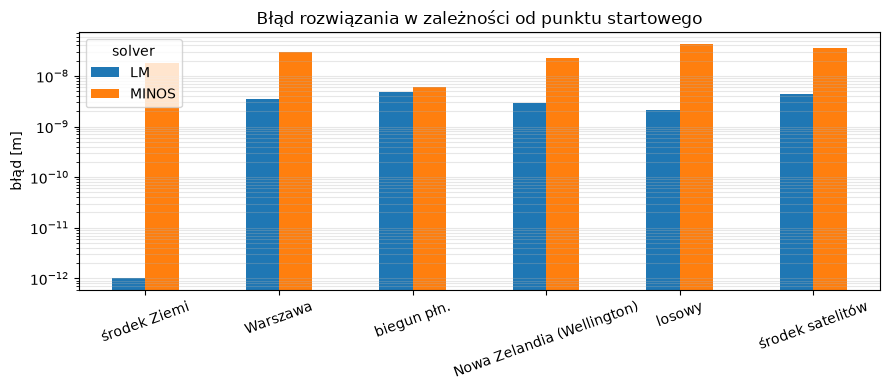

In [123]:
fig, ax = plt.subplots(figsize=(9, 4))
pivot = df_start.pivot(index="start", columns="solver", values="błąd [m]").loc[list(starts)]
pivot.clip(lower=1e-12).plot.bar(ax=ax, logy=True, rot=20)
ax.set(ylabel="błąd [m]", xlabel="", title="Błąd rozwiązania w zależności od punktu startowego")
ax.grid(axis="y", which="both", alpha=0.3)
plt.tight_layout()
plt.show()

Jak można zauważyć najmniejszy błąd pomiędzy rozwiązaniem a rozwiązaniem referencyjnym wystąpił w przypadku punktu startowego w środku ziemi dla solvera Levenberga-Marquardta. Nie powinno to dziwić, ponieważ rozwiązanie referencyjne też było wyznaczone tą metodą dla dla punktu startowego w środku ziemi z tolerancją wynoszącą właśnie $10^{-12}$. Pozostałe błędy są natomiast na tyle małe, że należy je rozumieć jako szum numeryczny, a nie rzeczywisty błąd. Współrzędne geograficzne, które podajemy do solverów są rzędu $10^6$, natomiast podwójna precyzja, z którą wykonywane są obliczenia ma eps = $2.2 \cdot 10^{16}$. Najmniejsza rozróżnialna zmiana położenia to rząd $10^{-9}, 10^{-10}$, a więc poziom nanometrów.

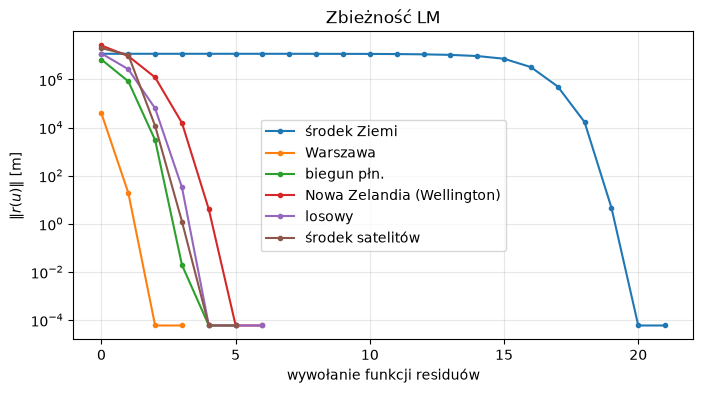

In [124]:
fig, ax = plt.subplots(figsize=(8, 4))
for start, X0 in starts.items():
    history = []
    def tracked(u, S, tau):
        r = residuals(u, S, tau)
        history.append(np.linalg.norm(r))
        return r
    least_squares(tracked, np.r_[X0, 0.0], jac=jacobian, args=(S, taus),
                  method="lm", xtol=1e-12, ftol=1e-12, gtol=1e-12)
    ax.semilogy(history, marker=".", label=start)
ax.set(xlabel="wywołanie funkcji residuów", ylabel=r"$\|r(u)\|$ [m]", title="Zbieżność LM")
ax.grid(which="both", alpha=0.3)
ax.legend()
plt.show()

Na powyższym wykresie można zauważyć, że dla punktu startowego ze współrzędnymi Warszawy solver LM zbiegł najszybciej, bo już po 2 krokach jego rozwiązanie miało błąd na poziomie milimetrów. Nie powinno to dziwić, ponieważ odbiornik znajdował się na południowy zachód od Warszawy. Tak samo najwolniejszą zbieżność miał test z punktem startowym w środku planety, który miał najdłuższą drogę do przejścia.

### Wpływ dokładności testu STOP

LM: `xtol = ftol = gtol = tol`

MINOS: `optimality_tolerance = feasibility_tolerance = tol`.

In [125]:
tols = [1e-1, 1e-2, 1e-3, 1e-4, 1e-6, 1e-8, 1e-10, 1e-12]
tol_starts = {k: starts[k] for k in ("środek Ziemi", "Warszawa")}

rows = []
for start, X0 in tol_starts.items():
    for name, solve in solvers.items():
        for tol in tols:
            r = solve(S, taus, u0=np.r_[X0, 0.0], tol=tol)
            rows.append({"start": start, "solver": name, "tol": tol, "F [m²]": r["F"],
                         "błąd [m]": err(r), "nfev": r["nfev"], "status": r["status"]})
df_tol = pd.DataFrame(rows)
df_tol

,start,solver,tol,F [m²],błąd [m],nfev,status
0,środek Ziemi,LM,1.000000e-01,6.724195e+13,6.378220e+06,2.0,`ftol` termination condition is satisfied.
1,środek Ziemi,LM,1.000000e-02,6.724195e+13,6.378220e+06,2.0,`ftol` termination condition is satisfied.
2,środek Ziemi,LM,1.000000e-03,6.724195e+13,6.378220e+06,2.0,`ftol` termination condition is satisfied.
3,środek Ziemi,LM,1.000000e-04,6.724195e+13,6.378220e+06,2.0,`ftol` termination condition is satisfied.
4,środek Ziemi,LM,1.000000e-06,1.766418e-09,0.000000e+00,22.0,`xtol` termination condition is satisfied.
5,środek Ziemi,LM,1.000000e-08,1.766418e-09,0.000000e+00,22.0,`xtol` termination condition is satisfied.
6,środek Ziemi,LM,1.000000e-10,1.766418e-09,0.000000e+00,22.0,`xtol` termination condition is satisfied.
7,środek Ziemi,LM,1.000000e-12,1.766418e-09,0.000000e+00,22.0,`xtol` termination condition is satisfied.
8,środek Ziemi,MINOS,1.000000e-01,1.085257e-06,9.952110e-04,NaN,solved
9,środek Ziemi,MINOS,1.000000e-02,1.085257e-06,9.952110e-04,NaN,solved


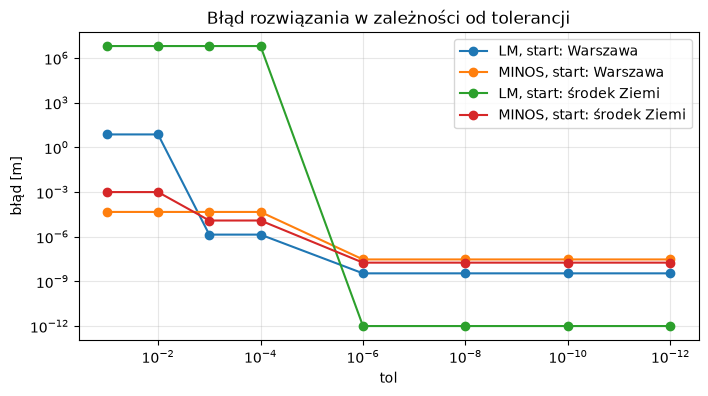

In [126]:
fig, ax = plt.subplots(figsize=(8, 4))
for (start, name), g in df_tol.groupby(["start", "solver"]):
    ax.loglog(g["tol"], g["błąd [m]"].clip(lower=1e-12), marker="o", label=f"{name}, start: {start}")
ax.invert_xaxis()
ax.set(xlabel="tol", ylabel="błąd [m]", title="Błąd rozwiązania w zależności od tolerancji")
ax.grid(which="both", alpha=0.3)
ax.legend()
plt.show()

### Wpływ zaburzeń w danych

Do czasów $\tau_i$ oraz wysokości satelitów $h_i$ dodajemy szum $\mathcal{N}(0, \sigma^2)$, po 20 prób dla każdego $\sigma$.
Start w $X_{ref}$, żeby mierzyć tylko wpływ danych.

In [127]:
n_trials = 20
u_ref = np.r_[X_ref, 0.0]

def noise_test(sigmas, perturb):
    rows, samples = [], {}
    for name, solve in solvers.items():
        rng = np.random.default_rng(0)
        for sigma in sigmas:
            Xs = np.array([solve(*perturb(rng, sigma), u0=u_ref)["X"] for _ in range(n_trials)])
            errs = np.linalg.norm(Xs - X_ref, axis=1)
            samples[name, sigma] = Xs
            rows.append({"solver": name, "sigma": sigma,
                         "średni błąd [m]": errs.mean(), "max błąd [m]": errs.max()})
    return pd.DataFrame(rows), samples

sigmas_t = [1e-10, 1e-9, 1e-8, 1e-7, 1e-6]
df_tau, samples_tau = noise_test(
    sigmas_t, lambda rng, s: (thetas, phis, heights, taus + rng.normal(0, s, N)))
df_tau.assign(**{"c·sigma [m]": C * df_tau["sigma"]})

TypeError: solve_lm() got multiple values for argument 'u0'

In [ ]:
sigmas_h = [1, 10, 100, 1000]
df_h, _ = noise_test(
    sigmas_h, lambda rng, s: (thetas, phis, heights + rng.normal(0, s, N), taus))
df_h

,solver,sigma,średni błąd [m],max błąd [m]
0,LM,1,1.390618,2.549958
1,LM,10,14.884401,33.847902
2,LM,100,141.039259,419.315224
3,LM,1000,1258.330581,2428.155244
4,MINOS,1,1.390619,2.549958
5,MINOS,10,14.884404,33.847873
6,MINOS,100,141.039270,419.315225
7,MINOS,1000,1258.330583,2428.155243


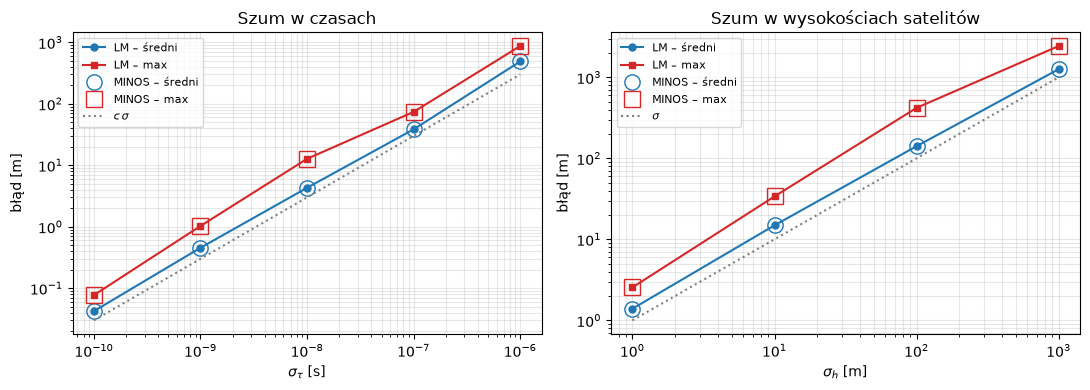

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, df, xlabel, scale in [(axes[0], df_tau, r"$\sigma_\tau$ [s]", C),
                              (axes[1], df_h, r"$\sigma_h$ [m]", 1)]:
    for (name, g), style in zip(df.groupby("solver"), [dict(ms=5), dict(ls="none", ms=11, mfc="none")]):
        ax.loglog(g["sigma"], g["średni błąd [m]"], marker="o", color="tab:blue", label=f"{name} – średni", **style)
        ax.loglog(g["sigma"], g["max błąd [m]"], marker="s", color="tab:red", label=f"{name} – max", **style)
    s = df["sigma"].unique()
    ax.loglog(s, scale * s, color="gray", ls=":", label=r"$c\,\sigma$" if scale == C else r"$\sigma$")
    ax.set(xlabel=xlabel, ylabel="błąd [m]")
    ax.grid(which="both", alpha=0.3)
    ax.legend(fontsize=8)
axes[0].set_title("Szum w czasach")
axes[1].set_title("Szum w wysokościach satelitów")
plt.tight_layout()
plt.show()

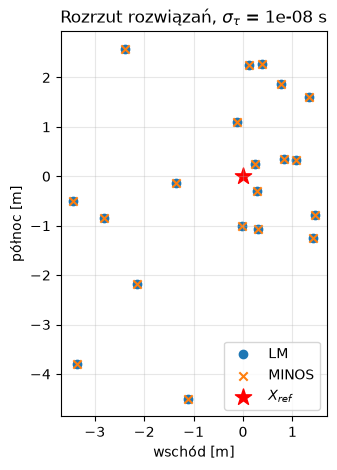

In [ ]:
th0, ph0 = np.radians(res_lm["theta"]), np.radians(res_lm["phi"])
east = np.array([-np.sin(ph0), np.cos(ph0), 0])
north = np.array([-np.sin(th0) * np.cos(ph0), -np.sin(th0) * np.sin(ph0), np.cos(th0)])

sigma = 1e-8
fig, ax = plt.subplots(figsize=(5, 5))
for name, marker in [("LM", "o"), ("MINOS", "x")]:
    d = samples_tau[name, sigma] - X_ref
    ax.scatter(d @ east, d @ north, marker=marker, label=name)
ax.scatter(0, 0, color="red", marker="*", s=150, label=r"$X_{ref}$")
ax.set(xlabel="wschód [m]", ylabel="północ [m]", aspect="equal",
       title=rf"Rozrzut rozwiązań, $\sigma_\tau$ = {sigma:g} s")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## Podsumowanie

Punkt wyznaczony na podstawie danych `dane_79.csv` to $\theta = 52.138145°$ N, $\phi = 20.712907°$ E, $h \approx 126$ m – okolice Brwinowa pod Warszawą. Błąd zegara wyniósł $b \approx 10^{-13}$ s, czyli praktycznie zero. Oba solvery dają to samo rozwiązanie, a różnica pomiędzy nimi jest pomijalnie mała ($10^{-8}$).


- **Punkt startowy:** z każdego testowanego startu (także ze środka Ziemi i z antypodów) oba solvery zbiegają do tego samego punktu. LM potrzebuje 5–7 wywołań funkcji z typowych startów i 22 ze środka Ziemi, gdzie przez kilkanaście kroków prawie stoi w miejscu (odległości do wszystkich satelitów są tam podobne).
- **Test STOP:** przy luźnej tolerancji ($\ge 10^{-4}$) LM startujący ze środka Ziemi kończy po pierwszym kroku (warunek `ftol`) z błędem ~6400 km. MINOS przy luźnej tolerancji daje błąd od mm do kilku m. Dla tol $\le 10^{-8}$ oba solvery osiągają dokładność poniżej $10^{-7}$ m, a dalsze zmniejszanie tolerancji nic nie zmienia.
- **Zaburzenia danych:** błąd położenia rośnie liniowo z szumem. Szum czasu $\sigma_\tau$ daje średni błąd ok. $1.5\,c\,\sigma_\tau$ (1 ns → ok. 0.45 m), a szum wysokości satelitów $\sigma_h$ daje ok. $1.4\,\sigma_h$. Wyniki LM i MINOS są tu identyczne – o dokładności decydują dane, nie solver.